# 04 · AerSimulator QNN — parametreli şablon

**Amaç:** Devreyi bir kez transpile edip her çağrıda parametre bağlayarak tekrarlanan derleme maliyetini azaltmak; merkezi sonlu fark ile eğitim yapmak.

**Okuma notu:** Gürültü modeli eklenmemiş Aer simülasyonudur. Ölçüm örneklemesi ile fiziksel cihaz gürültüsü farklıdır. Son RY katmanında yalnız q0 açısı ideal q0 marjinalini etkiler; diğer üç açı bu okumaya katkı sağlamaz.

**Durum:** Staj çalışması arşivi. Aşağıdaki çıktılar ZIP içinde kayıtlı geçmiş çalıştırmalara aittir; bu yayına hazırlık sırasında üretilmiş yeni deney sonuçları değildir. Deney kodu ve eski açıklamalar gelişim sürecini göstermek için korunmuştur; yöntem düzeltmeleri ve sınırlılıklar için [çalışma rehberini](../../docs/CALISMA_REHBERI.md), [sonuçları](../../docs/SONUCLAR.md) ve [yöntem incelemesini](../../docs/YONTEM_VE_SINIRLAR.md) okuyun.

**English:** Historical internship experiment. See the [English overview](../../README_EN.md). Saved outputs are historical evidence, not a fresh reproducibility claim.



## Hedef: Basit bir QNN ile iris veri kümesi üzerinde 2'li sınıflandırma yaparak simülasyonda çalıştırmak.

Bu çalışmada, Iris veri kümesi kullanılarak ikili sınıflandırma (Setosa vs Versicolor) problemi için basit bir Quantum Neural Network (QNN) modeli kurulmuştur. Veri ölçeklendirme işlemleri sonrası özellikler kuantum devresine gömülerek sınıflandırma yapılmıştır.

Kodun 3. versiyonunda, önceki sürümde kullanılan StatevectorSampler yerine, Qiskit AerSimulator tercih edilmiştir. Bu değişiklikle model, daha gerçekçi bir simülasyon ortamında çalıştırılabilmektedir.

**Statevector (StatevectorSampler)**

* Kuantum devresinin matematiksel durum vektörünü verir.
* Gürültüsüz ve deterministik çalışır, yani her olasılık dağılımını doğrudan hesaplar.
* Eğitim için hızlıdır fakat gerçek donanımda gözlemlenen ölçüm belirsizliğini içermez.

**AerSimulator**

* Kuantum donanımındaki ölçüm sürecini taklit eder.
* Devre çalıştırıldığında, 0 ve 1 gibi bit çıktılarının kaç kez gözlendiği (counts) üzerinden olasılık dağılımı elde edilir.
* Daha gerçekçi sonuç verir çünkü ölçüm rastlantısallığını simüle eder.

Bu versiyon, kuantum modelini daha donanım-uyumlu bir yaklaşımla test etmeyi ve performansını gözlemlemeyi amaçlamaktadır.


Simülatör (AerSimulator, StatevectorSimulator) → Bilgisayarında, kuantum devreyi matematiksel olarak taklit ediyor. Gürültü eklenmezse sonuçlar “ideal”.

Gerçek cihaz (IBM Quantum donanımı gibi) → Fiziksel qubit’ler (süperiletken devreler, iyon tuzakları vs.) üzerinde çalışıyor. Bunların kısıtlı kapı seti var (ör. yalnızca CX, U gibi temel kapılar). Ayrıca her qubit diğer tüm qubitlerle doğrudan bağlı değil (topoloji kısıtlı). Bu yüzden transpile zorunlu → devre  yazılan soyut kapılardan, cihazın anlayacağı fiziksel kapılara çevriliyor.


In [1]:
import sklearn
import qiskit
import numpy as np
import matplotlib

print("scikit-learn version:", {sklearn.__version__})
print("Qiskit version:", {qiskit.__version__})
print("NumPy version:", {np.__version__})
print("Matplotlib version:", {matplotlib.__version__})

#scikit-learn version: {'1.7.1'}
#Qiskit version: {'1.2.4'}
#NumPy version: {'2.1.3'}
#Matplotlib version: {'3.10.5'}

scikit-learn version: {'1.7.1'}
Qiskit version: {'1.2.4'}
NumPy version: {'2.1.3'}
Matplotlib version: {'3.10.5'}


In [38]:
from sklearn import model_selection, datasets, svm
from sklearn.preprocessing import MinMaxScaler

from qiskit.circuit import ParameterVector
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator


import copy
import numpy as np
import matplotlib.pyplot as plt

Kullanılan her kütüphanenin versiyon bilgileri ayrıca not edilmiştir. Bunun nedeni, özellikle Qiskit’in sık sık API değişikliklerine gitmesidir.

Çalışmada kullanılan kütüphane sürümlerinin not edilmesi, ileride yeniden çalıştırma veya karşılaştırma yaparken tutarlılığı korumak açısından önemlidir.

* Kuantum bilişim henüz erken gelişim aşamasında (yaklaşık 20 yıllık bir alan).
* En iyi yöntemler ve standartlar henüz tam oturmuş değil.
* Donanım çok hızlı ilerlediği için yazılım kütüphaneleri sürekli güncelleniyor.
* Araştırma odaklı bir alan olduğundan, yenilik kararlılıktan daha öncelikli.

Qiskit 3–6 ayda bir API değişiklikleri yapılıyor, çünkü alan hâlâ keşif ve standartlaşma sürecinde.

In [4]:
#iris veri setini ekleyelim 

iris = datasets.load_iris()  

X = iris.data[0:100]
Y = iris.target[0:100]

# test-train olarak ayıralım
X_train, X_test, Y_train, Y_test = model_selection.train_test_split(
    X, Y, test_size=0.33, random_state=42
)


### Rotation Encoding

Klasik sayısal verileri kuantum devresine gömmek için rotation (döndürme) kapıları kullanılır.

Örn: qc.rx(5.2, 0) → q0 qubit’i X ekseni etrafında 5.2 rad döner → 5.2 sayısı qubit’in durumuna encode edilmiş olur.

Rx, Ry, Rz kapıları qubit’i Bloch küresi üzerinde sırasıyla X, Y, Z eksenleri etrafında döndürür.

#### Formül:
* Rx(θ) → X ekseni etrafında θ
* Ry(θ) → Y ekseni etrafında θ
* Rz(θ) → Z ekseni etrafında θ

Buradaki θ (teta), aslında senin seçtiğin sayısal veriye veya öğrenilen parametreye bağlıdır. Yani:

**Data encoding (veri gömme) durumunda:**
θ → klasik veriden gelir.
Örn: sepal length = 5.2 → θ = 5.2 rad → Rx(5.2).

**Variational circuit (öğrenilen devre) durumunda:**
θ → modelin öğrenmeye çalıştığı parametredir.
Eğitim sırasında optimizer bu açıları günceller.

Dolayısıyla Rx, Ry, Rz kapılarındaki θ açıları birbirinden bağımsızdır ve farklı olabilir. Bir qubit için X etrafında 1.2 rad dönebilirsin, aynı qubit için Y etrafında 2.7 rad döndürebilirsin. Her qubit’in açısı farklı veriden ya da farklı parametreden gelebilir.

Yani, θ sabit bir açı değildir; veriyle, qubit’le veya öğrenme parametresiyle değişir. Bu yüzden her Rx/Ry/Rz kapısının θ değeri farklı olabilir. Rx, Ry, Rz arasındaki fark sadece dönüş eksenidir.


Ancak, 
* Rx ve Ry → qubit’in hem amplitüdünü hem fazını etkiler. Yani qubit gerçekten yeni süperpozisyonlara girer.
* Rz → sadece fazı değiştirir, |0⟩ ve |1⟩ olasılıklarını değiştirmez.

Bu yüzden, ölçüm sonucunda Rz dönüşleri tek başına gözlemlenemez. Ancak başka kapılarla birleştiğinde etkisini gösterebilir. Bu nedenle QML Literatüründe, Veri encoding için genelde Rx veya Ry tercih edilir çünkü daha doğrudan gözlemlenebilir farklılıklar yaratır.

Rz ise çoğunlukla variational ansatz (öğrenilecek parametreler) kısmında kullanılır. Ama doğru kombinasyonlarda data encoding’de de işe yarayabilir.

Yani evet, veriyi Rz’ye gömebilirsin ama tek başına ölçümde gözükmez. Bu nedenle daha çok Rx/Ry tercih edilir, Rz faz katkısı olarak destekleyici rol oynar.

#### Neden [0, π] veya [0, 2π] Ölçeklendiriyoruz?

* π (180°): Yarım dönüş → daha kompakt temsil

* 2π (360°): Tam dönüş → tüm olasılıkları kapsar

Veriler bu aralıklara ölçeklenir böylece tekrarlar önlenir, tutarlı temsil sağlanır ve modelin öğrenmesi kolaylaşır.

In [5]:
# Feature scaling: [0, pi] 

scaler = MinMaxScaler(feature_range=(0, np.pi))
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)


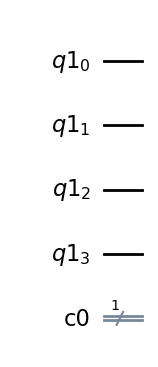

In [6]:
N = 4  # Özellik sayısı (her özellik için bir qubit kullanacağız)
q = QuantumRegister(N)       # N qubitlik kuantum register (girdi)
c = ClassicalRegister(1)     # 1 bitlik klasik register (çıktı), ölçüm sonucunu kaydetmek için
qc = QuantumCircuit(q, c)    # Kuantum devresini oluştur

qc.draw("mpl")  # Devreyi görselleştir

In [7]:
N = 4  

def feature_map(X):

    q = QuantumRegister(N)
    c = ClassicalRegister(1)
    qc = QuantumCircuit(q, c)

    for i, x in enumerate(X):
        qc.rx(x, i)
    return qc, c

# Bu fonksiyonla feature_map(X) fonksiyonu = girdi vektörünü al, 
# N qubit’e rotation kapılarıyla encode et, devreyi döndür.

#### Devre Yapısı ve Feature Map
* q (QuantumRegister) → Qubitleri tutuyor. Örneğin N=4 → q = [q0, q1, q2, q3]. Bunlar, veriyi encode ettiğin “kuantum taşıyıcılar”.

* c (ClassicalRegister) → Ölçüm sonuçlarını saklıyor. Kaç qubit’i ölçersen, o kadar klasik bit gerekir. Bu kodda sadece 1 klasik bit var yani sadece bir qubit ölçülecek.

* qc (QuantumCircuit) → Asıl kuantum devresi. İçine q ve c’yi koyarak devreyi tanımlıyorsun. Sonrasında qc.rx(x, i) diyerek q[i] qubitine rotation kapısı uyguluyorsun.


**Bu devrede kullanılanlar:**

* 4 qubit → Iris verisindeki 4 özelliği encode etmek için.
* 1 klasik bit → Ölçüm sonucunu (0 veya 1) tutmak için.

**Feature Map:**

Klasik veriyi kuantum devresine gömme (encoding/embedding) işlemidir. Klasik girdiler qubitlere Rx dönüş kapıları ile encode edilir.

Feature map = ML’deki “input layer”

Variational circuit = ML’deki “hidden layers / model ağırlıkları”


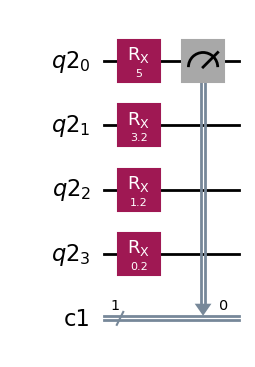

In [8]:
qc, c = feature_map(X_train[5])   # 6. gözlemi feature_map ile devreye encode et
qc.measure(0, c)  # q0 qubitini ölç ve sonucu c’ye (classical register) yaz
qc.draw("mpl")

Kuantum Devresini oluşturduk, ve bu devreyi ölçmemiz gerekiyor çünkü bir çıktı elde etmeliyiz. Devreyi çalıştırıp sadece qubitleri döndürmek yetmez. En sonunda ölçüm (measurement) yaparak qubit’in kuantum durumunu klasik bir sayıya (0 veya 1) dönüştürmemiz gerekir.

Bu ölçüm(çıktı) bizim quantum devremizin tahmini olacak. 

Neden burada sadece 6. örnek? Çünkü test amaçlı tek gözlem seçtik. Eğitim aşamasında her örneği sırayla feature_map’ten geçireceğiz.

Bu haliyle sadece “fonksiyon çalışıyor mu, devre doğru encode ediyor mu?” diye kontrol yapıyoruz.

#### **qc.measure(0, c)**

q0 qubitini ölç ve Ölçüm sonucucunu c (classical register) içine yaz.
Sonuç ya 0 ya da 1 olur.

**Neden sadece q0 ölçülüyor?**

Ölçmek, kuantum bilgisayarda “klasik bilgiye çevirme” demek. Eğer tüm qubitleri ölçersen, her birinden bir bit alırsın toplamda 4 bitlik çıktı çıkar. Ama problemimiz binary (2 sınıf), yani tek bitlik çıktı yeterli. Tüm qubitleri ölçmek fazladan bilgi getirmez, sadece devreyi karmaşıklaştırır.

Başta diğer qubitler de veriyi encode eder. Entanglement (CNOT, CZ) ve parametreli dönüşümler sayesinde bu bilgiler q0’a aktarılır. Sonuçta q0’ın çıktısı tüm özelliklerin birleşik etkisini temsil eder.

Yani ölçüm tek qubit’te yapılır ama o qubit aslında tüm verinin işlenmiş halini taşır. Dolayısıyla aslında model tek özelliğe bakmıyor, tüm özellikleri işleyip sonucunu tek bir qubit’te yoğunlaştırıyor.

Ayrıca 1 qubit ölçüyorsan, hangi qubit’i seçtiğin önemlidir. Çünkü devredeki bilginin nerede “yoğunlaştığına” bağlıdır. Eğer tüm qubitleri ölçüyorsan, zaten tüm bilgiyi okuyorsun, o yüzden hangi qubit olduğu fark etmez.

* Simetrik devrelerde: Fark etmez, genelde q0 ölçülür.
* Asimetrik devrelerde: Ölçüm, bilgi akışının sonunda seçilen qubit’te yapılır.
* Pratikte: QML’de çoğunlukla q0 ölçülür; entanglement sayesinde diğer qubitlerin bilgisi oraya taşınır.
* Tek qubit ölçüyorsan, devreyi öyle tasarlamalısın ki tüm bilgi o qubit’e aktarılsın.

In [ ]:
# Öğrenebilen bir devre oluşturalım

def variational_circuit(qc, theta):
    for i in range(N-1):
        qc.cx(i, i+1)   # CNOT, 0→1, 1→2, 2→3... bağlıyoruz
    qc.cx(N-1, 0)       # Son qubit'i ilk qubit'e bağla (halka yap)

    for i in range(N):
        qc.ry(theta[i], i)   # Her qubit'e theta[i] kadar döndür, öğrenilebilir Ry(θ)
    return qc

#### Variational Circuit (Öğrenebilen Devre)

**Theta (θ) parametreleri:**

Klasik ML’deki ağırlıklar (weights) gibidir. Kuantum devresinde öğrenilebilir açılar olarak yer alır. Eğitim sırasında optimizer (SGD, COBYLA, SPSA vb.) bu açıları güncelleyerek loss’u düşürmeye çalışır.

**Yapısı:**

* Parametreli kapılar: Genelde Rx/Ry/Rz(θ) dönüşleri her qubit’e öğrenilebilir açı uygulanır.

* Entanglement (CNOT/CZ): Qubitler birbirine bağlanır, böylece bilgi tek bir qubitle sınırlı kalmaz.

* Ring (halka) bağlantı: 0–1–2–…–N-1–0 → minimal bağlantıyla tüm qubitler birbirine etkileşimli hale gelir.

**CNOT zincirleri:**

Qubitleri birbirine “arkadaş zinciri” gibi bağlar. Böylece bir qubit’in durumu diğerlerini etkiler. Bu etkileşim, modelin daha karmaşık karar sınırlarını öğrenmesini sağlar.

Not: Yeni Qiskit versiyonlarında qc.cnot(...) yerine qc.cx(...) kullanılıyor. Biz de bu kodda cx kullandık ama internetteki pek çok kaynakta cnot olarak gördüm dikkat edin.


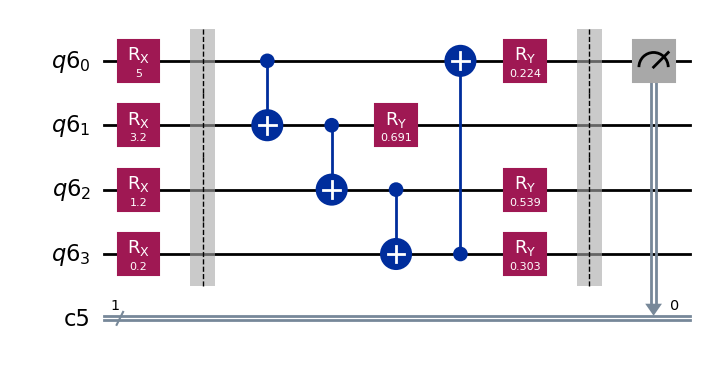

In [14]:

qc, c =feature_map(X_train[5])

qc.barrier()

qc = variational_circuit(qc, np.random.rand(N))

qc.barrier()

# measurement operator
qc.measure(0,c)

# Devreyi çizelim
qc.draw("mpl")



**qc.barrier()**

Qiskit devreleri transpiler tarafından optimize edilir. Kapılar yeniden sıralanabilir, gereksiz olanlar silinebilir. Bu genelde faydalıdır ama bazen devrenin belirli kısımlarını ayrı görmek veya sıra garantilemek isteriz.

Barrier’ın rolü:

* Transpiler’in o noktadaki kapıları yer değiştirmesini engeller.
* Görsel olarak devreyi bölümlere ayırır (ör. Feature Map ↔ Variational Circuit).
* Bir çeşit “çit” gibi çalışır: buradan öncesi = A blok, buradan sonrası = B blok.

Kısaca qc.barrier() devrede optimizasyonu durduran ayraçtır; hem görsel düzen sağlar hem de kapıların sırasını korur.

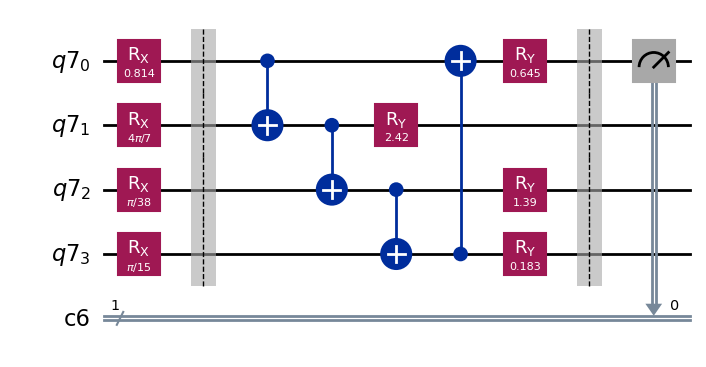

In [15]:
theta = np.random.rand(N) * np.pi  # Rastgele theta değerleri
# üstteki görselle farkı burada theta değerleri 0-pi arasında rastgele seçiliyor

qc, c = feature_map(X_train_s[5]) 

qc.barrier()

qc = variational_circuit(qc, theta)

qc.barrier()

qc.measure(0, c[0])  # q0 -> c0


# Devreyi çizelim
qc.draw("mpl")



In [16]:
# AerSimulator ile çalıştıralım
from qiskit import transpile

backend = AerSimulator()
tqc = transpile(qc, backend)
shots = 2048
res = backend.run(tqc, shots=shots, seed_simulator=42).result()
counts = res.get_counts(tqc)

nshots = sum(counts.values())
p1 = counts.get('1', 0) / nshots
print("counts:", counts)
print("p(1):", p1)

counts: {'0': 826, '1': 1222}
p(1): 0.5966796875


#### transpile Neden Gerekli?

Yazdığımız devre (qc) soyut kapılarla tanımlanır (Rx, Ry, CNOT, vb.). Ama her backend (simülatör veya gerçek cihaz) sadece kendi desteklediği kapıları çalıştırabilir.

Transpile, Backend’in anlayacağı kapılara çevirir, Donanımın bağlantı yapısına (hangi qubit hangisiyle bağlı) uydurur, Gereksiz kapıları silip devreyi optimize eder.

transpile(qc, backend) = devreyi backend’in anlayacağı dile çevirmek ve kısaltmak.


**Simülasyonda ve Gerçek Donanımda Fark**

- AerSimulator: Aslında çoğu kapıyı direkt anlayabilir → transpile çoğu zaman sadece optimizasyon yapar.

- Gerçek cihaz: Transpile zorunlu, çünkü cihazın kısıtlı kapı seti ve topolojisi vardır. Örneğin bazı qubit’ler doğrudan bağlı değildir → transpiler araya SWAP ekler.


In [17]:
print(Y_train[5])

0


In [ ]:
"""theta = np.random.rand(N) * np.pi

def quantum_nn(X, theta, shots=2048):
    
    # Feature map
    qc, c = feature_map(X)

    qc.barrier()

    # Variational circuit
    qc = variational_circuit(qc, theta)

    qc.barrier()
    
    #  Ölçüm
    qc.measure(0, c[0])   # sadece q0 ölçülüyor (binary)

    # AerSimulator
    backend = AerSimulator()
    tqc = transpile(qc, backend)

    # Çalıştır
    job = backend.run(tqc, shots=shots, seed_simulator=42)
    result = job.result()
    counts = result.get_counts(tqc)

    # Olasılık p(1)
    p1 = counts.get('1', 0) / shots
    return p1
"""

# Bu kodu değiştirerek alttakini işleme alıyorum 
# çünkü alttaki daha iyi, her seferinde transpile etmiyor

In [26]:
# Parametreler için yer tutucular belirliyoruz 
# rx(phi) ve ry(theta) için
phi   = ParameterVector('phi', N)      # veri için yer tutucular
theta = ParameterVector('theta', N)    # ağırlık parametreleri

# Devre şablonunu oluşturuyoruz
qc, c = feature_map(phi)               # X yerine phi parametreleri
qc.barrier()
qc = variational_circuit(qc, theta)    # theta parametreleri
qc.barrier()
qc.measure(0, c[0])

# Hızlanması için sadece bir kez transpile ediliyor
backend = AerSimulator()
tqc = transpile(qc, backend)

# Fonksiyona her seferinde sadece parametreler bağlanıyor
def quantum_nn(x_vals, theta_vals, shots=2048):
    bind = {phi[i]: float(x_vals[i]) for i in range(N)}
    bind |= {theta[j]: float(theta_vals[j]) for j in range(N)}

    tqc_bound = tqc.assign_parameters(bind, inplace=False)

    job = backend.run(
        tqc_bound,
        shots=shots,
        seed_simulator=42
    )
    counts = job.result().get_counts()
    nshots = sum(counts.values())
    return counts.get('1', 0) / nshots if nshots else 0.0


In [29]:
# prediction için
theta_vals = np.random.rand(N) * np.pi       # öğrenilebilir parametreler
x_vals     = X_train_s[5]                    # ölçeklenmiş özellikler

prediction = quantum_nn(x_vals, theta_vals)
print("Tahmin p(1):", prediction)


Tahmin p(1): 0.53076171875


In [31]:
target = Y_train[5]
target

np.int64(0)

X_train_s[5] → ölçeklenmiş özellik vektörün (girdi).

Y_train[5] → o örneğin gerçek etiketi (target).

QNN’in çıktısı prediction = p(1) (0 ile 1 arasında olasılık). bu nedenle girdiyi ölçekledik. target zaten 0 veya 1 yani ground-truth (doğru cevap).

QNN prediction üretir, target ise gerçek sınıftır → loss/accuracy hesaplamasında karşılaştırılır.

In [49]:
def loss(prediction, target):
    """Mean Squared Error loss"""
    return (prediction - target) ** 2

print("Loss:", loss(prediction, target))

Loss: 0.45536136627197266


In [50]:
def gradient(X, Y, theta, delta=1e-2):
    """
    Finite difference (central) gradient.
    X: ölçeklenmiş tek örnek (shape: [N])
    Y: 0/1 etiket
    theta: np.array, uzunluk N 
    """
    theta = np.asarray(theta, dtype=float)
    grad = np.zeros_like(theta, dtype=float)

    # Baz kayıp (isteğe bağlı: sadece kontrol için)
    pred_base = quantum_nn(X, theta)
    loss_base = loss(pred_base, Y)

    for i in range(len(theta)):
        th_plus  = theta.copy(); th_plus[i]  += delta
        th_minus = theta.copy(); th_minus[i] -= delta

        p_plus  = quantum_nn(X, th_plus)
        p_minus = quantum_nn(X, th_minus)

        # central difference
        g_i = (loss(p_plus, Y) - loss(p_minus, Y)) / (2.0 * delta)
        grad[i] = g_i

    return grad

In [51]:
def accuracy(X, Y, theta):
    """
    X: ölçeklenmiş örnekler (X_train_s / X_test_s)
    Y: {0,1} etiketler
    theta: öğrenilebilir parametre(ler)
    """
    n = len(Y)
    if n == 0:
        return 0.0

    correct = 0
    for X_i, Y_i in zip(X, Y):
        p1 = quantum_nn(X_i, theta)           # p(1)
        y_hat = 1 if p1 >= 0.5 else 0         # threshold
        correct += (y_hat == int(Y_i))        # True->1, False->0

    return correct / n


In [52]:
def train_simple_qnn(X_train_s, Y_train, X_test_s, Y_test,
                     epochs=10, eta=0.05,
                     theta_init='random',   # 'ones' veya 'random'
                     delta=1e-2):         # finite-difference adımı (central diff)
    """
    Basit QNN training (L yok → len(theta)=N)
    Girdi X_* mutlaka ÖLÇEKLİ (örn. MinMaxScaler(0, π)).
    Loss = MSE kullanır.
    """
    # --- theta başlatma ---
    if theta_init == 'random':
        theta = np.ones(N, dtype=float)
    elif theta_init == 'ones':
        theta = np.random.rand(N).astype(float) * np.pi
    else:
        raise ValueError("theta_init 'ones' veya 'random' olmalı")

    loss_list, train_acc_list, test_acc_list = [], [], []

    print("Epoch \t Loss \t Training Acc \t Test Acc")
    print("-" * 50)

    for epoch in range(epochs):
        # SGD için veri karıştır
        idx = np.random.permutation(len(Y_train))
        X_tr = X_train_s[idx]
        Y_tr = Y_train[idx]

        loss_tmp = []

        for X_i, Y_i in zip(X_tr, Y_tr):
            # 1) Forward: p(|1⟩)
            p1 = quantum_nn(X_i, theta)

            # 2) Loss: MSE (önceden tanımlı loss(pred, target))
            ell = loss(p1, int(Y_i))          # {0,1}
            loss_tmp.append(float(ell))

            # 3) Gradient: central difference
            g = gradient(X_i, int(Y_i), theta, delta=delta)

            # 4) Güncelleme
            theta = theta - eta * g

        # Epoch sonu metrikler
        avg_loss = float(np.mean(loss_tmp)) if loss_tmp else 0.0
        train_acc = accuracy(X_train_s, Y_train, theta)
        test_acc  = accuracy(X_test_s,  Y_test,  theta)

        loss_list.append(avg_loss)
        train_acc_list.append(train_acc)
        test_acc_list.append(test_acc)

        print(f"{epoch:5d} \t {avg_loss:.3f} \t {train_acc:11.3f} \t {test_acc:8.3f}")

    return theta, loss_list, train_acc_list, test_acc_list


#### train_simple_qnn(...)

Amaç, QNN’in parametrelerini (theta), Stochastic Gradient Descent (SGD) mantığıyla eğitmek ve her epoch sonunda:
* loss
* train accuracy
* test accuracy
değerlerini raporlamak.

**Girdiler**

- X_train, Y_train : Eğitim verisi (özellikler ve etiketler, {0,1})
- X_test, Y_test : Test verisi
- epochs : Eğitim boyunca dataset’in kaç kez üzerinden geçileceği
- eta : Öğrenme oranı (learning rate, hiperparametre)

**Adımlar**

1. Başlatma

2. theta = np.ones(N) → parametreler 1 ile başlatılır (tutorial uyumlu).

3. Kayıt için boş listeler hazırlanır: loss_list, train_acc_list, test_acc_list.

4. Epoch döngüsü (her epoch için):

5. loss_tmp = [] → o epoch’taki tüm örneklerin loss değerlerini tutar.

6. Eğitim örnekleri üzerinde tek tek dolaşılır (stochastic güncelleme):
   a) prediction = quantum_nn(X_i, theta) → ileri geçiş, p(|1⟩)
   b) current_loss = loss(prediction, Y_i) → BCE loss
   c) grad = gradient(X_i, Y_i, theta) → finite difference ile ∂L/∂θ
   d) theta = theta − eta * grad → SGD güncellemesi



**Epoch sonunda:**

* avg_loss = mean(loss_tmp) → ortalama loss

* train_acc = accuracy(X_train, Y_train, theta)

* test_acc = accuracy(X_test, Y_test, theta)

* Metrikler kaydedilir ve ekrana yazdırılır.


**Fonksiyon sonunda:**

* return theta, loss_list, train_acc_list, test_acc_list

* Güncellenmiş parametreler (theta)

* Epoch bazlı loss / accuracy seyirleri (plot için kullanılabilir) döner.

In [53]:
#  Görselleştirme Fonksiyonu

def plot_training_simple(loss_list, train_acc_list, test_acc_list, savepath=None):
    """
    Training sonuçlarını görselleştirir.
    - loss_list:MSE loss (epoch başına)
    - train_acc_list, test_acc_list: [0,1] aralığında doğruluk
    - savepath: dosya yolu verilirse grafiği kaydeder
    """
    # Koruma: boş liste veya uzunluk farkı
    if not loss_list or not train_acc_list or not test_acc_list:
        raise ValueError("Listeler boş olamaz.")
    m = min(len(loss_list), len(train_acc_list), len(test_acc_list))
    loss_list        = loss_list[:m]
    train_acc_list   = train_acc_list[:m]
    test_acc_list    = test_acc_list[:m]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    # Loss (BCE)
    ax1.plot(loss_list, linewidth=2, label='Training Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss (MSE)')
    ax1.set_title('Training Loss Over Time')
    ax1.grid(True, alpha=0.3)
    ax1.legend()

    # Accuracy
    ax2.plot(train_acc_list, linewidth=2, label='Training Accuracy')
    ax2.plot(test_acc_list,  linewidth=2, label='Test Accuracy')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy')
    ax2.set_title('Accuracy Over Time')
    ax2.grid(True, alpha=0.3)
    ax2.legend()
    ax2.set_ylim(0, 1)

    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, bbox_inches='tight', dpi=150)
    plt.show()
    return fig, (ax1, ax2)

In [59]:
# Eğitim çağrısı (örnek)
optimal_theta, losses, train_accs, test_accs = train_simple_qnn(
    X_train_s, Y_train, X_test_s, Y_test,
    epochs=10, eta=0.05
)


Epoch 	 Loss 	 Training Acc 	 Test Acc
--------------------------------------------------
    0 	 0.296 	       0.284 	    0.182
    1 	 0.233 	       0.821 	    0.879
    2 	 0.198 	       0.821 	    0.879
    3 	 0.185 	       0.821 	    0.879
    4 	 0.181 	       0.821 	    0.879
    5 	 0.178 	       0.821 	    0.879
    6 	 0.175 	       0.821 	    0.879
    7 	 0.174 	       0.821 	    0.879
    8 	 0.173 	       0.806 	    0.879
    9 	 0.172 	       0.806 	    0.879


Final Training Accuracy: 0.8059701492537313
Final Test Accuracy: 0.8787878787878788
Final Loss: 0.17167949676513672


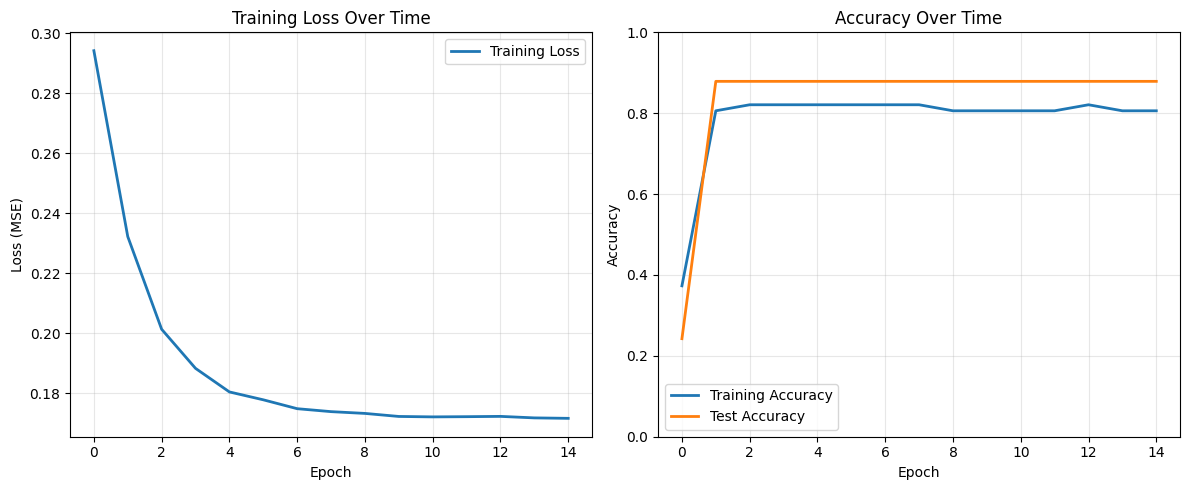

(<Figure size 1200x500 with 2 Axes>,
 (<Axes: title={'center': 'Training Loss Over Time'}, xlabel='Epoch', ylabel='Loss (MSE)'>,
  <Axes: title={'center': 'Accuracy Over Time'}, xlabel='Epoch', ylabel='Accuracy'>))

In [58]:
# Son loss ve accuracy değerleri
print("Final Training Accuracy:", train_accs[-1])
print("Final Test Accuracy:", test_accs[-1])
print("Final Loss:", losses[-1])

# Grafik çiz
plot_training_simple(losses, train_accs, test_accs)


In [56]:
# Test setinden birkaç tahmin
for i in range(5):
    pred = quantum_nn(X_test_s[i], optimal_theta)  # dikkat: ölçekli X
    actual = Y_test[i]
    predicted_class = 1 if pred >= 0.5 else 0
    print(f"Sample {i+1}: Pred={pred:.3f} → Class={predicted_class}, Actual={actual}")


Sample 1: Pred=0.728 → Class=1, Actual=1
Sample 2: Pred=0.761 → Class=1, Actual=1
Sample 3: Pred=0.392 → Class=0, Actual=1
Sample 4: Pred=0.536 → Class=1, Actual=0
Sample 5: Pred=0.218 → Class=0, Actual=0


#### 🔹 İlk Deneme

Final Training Accuracy: %88.1

Final Test Accuracy: %84.8

Final Loss (MSE): 0.206

Grafikler:

Loss 0.20 civarına kadar düşmüş, sonra plato yapmış.

Training ve Test acc birbirine yakın.

Yorum: Model uzun süre eğitilmiş, ama fazla ilerleme olmamış. öğrenme doygunluğa ulaşmış.

#### 🔹 Bu Kod

Final Training Accuracy: %80.6

Final Test Accuracy: %87.9

Final Loss (MSE): 0.172

Grafikler:

Loss daha düşük (0.172), yani olasılık tahminleri daha isabetli.

Test acc daha yüksek (%87.9), Train acc biraz düşük kalsa da genelleme daha iyi.

Yorum: Daha kısa eğitim, daha iyi test başarımı sağlamış. Bu, modelin fazla uzun eğitilince “train’e takılıp kalma” eğilimini gösteriyor.